#STUDENT NAME: 

In [37]:
#!/usr/bin/env python3
# -*- coding:utf-8 -*-
"""
Created on Tue Sep  4 10:23:50 2018
Modified Oct 2020, Oct 2021, Oct 2023, Oct 2026

@author: Said Ladjal,Isabelle Bloch
"""

'\nCreated on Tue Sep  4 10:23:50 2018\nModified Oct 2020, Oct 2021, Oct 2023, Oct 2026\n\n@author: Said Ladjal,Isabelle Bloch\n'

In [38]:
import numpy as np
import platform
import tempfile
import os
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import io as skio

import skimage.morphology as morpho
from skimage.segmentation import watershed
from skimage.draw import line
import skimage.feature as skf
from scipy import ndimage as ndi

In [39]:
# Useful functions


def viewimage(im, normalise=True, MINI=0.0, MAXI=255.0):
    """Cette fonction fait afficher l'image EN NIVEAUX DE GRIS
    dans gimp. Si un gimp est deja ouvert il est utilise.
    Par defaut normalise=True. Et dans ce cas l'image est normalisee
    entre 0 et 255 avant d'être sauvegardee.
    Si normalise=False MINI et MAXI seront mis a 0 et 255 dans l'image resultat
    Uses gimp to display images
    """
    imt = np.float32(im.copy())
    if platform.system() == "Darwin":  # on est sous mac
        prephrase = "open -a GIMP "
        endphrase = " "
    elif (
        platform.system() == "Linux"
    ):  # SINON ON SUPPOSE LINUX (si vous avez un windows je ne sais comment faire. Si vous savez dites-moi.)
        prephrase = "gimp "
        endphrase = " &"
    elif platform.system() == "Windows":
        prephrase = 'start /B "D:/GIMP/bin/gimp-2.10.exe" -a '  # Remplacer D:/... par le chemin de votre GIMP
        endphrase = ""
    else:
        print("Systeme non pris en charge par l affichage GIMP")
        return "erreur d afficahge"
    if normalise:
        m = imt.min()
        imt = imt - m
        M = imt.max()
        if M > 0:
            imt = imt / M

    else:
        imt = (imt - MINI) / (MAXI - MINI)
        imt[imt < 0] = 0
        imt[imt > 1] = 1

    nomfichier = tempfile.mktemp("TPIMA.png")
    commande = prephrase + nomfichier + endphrase
    skio.imsave(nomfichier, imt)
    os.system(commande)


def viewimage_color(im, normalise=True, MINI=0.0, MAXI=255.0):
    """Cette fonction fait afficher l'image EN NIVEAUX DE GRIS
    dans gimp. Si un gimp est deja ouvert il est utilise.
    Par defaut normalise=True. Et dans ce cas l'image est normalisee
    entre 0 et 255 avant d'être sauvegardee.
    Si normalise=False MINI(defaut 0) et MAXI (defaut 255) seront mis a 0 et 255 dans l'image resultat
    Same as before for color images.
    """
    imt = np.float32(im.copy())
    if platform.system() == "Darwin":  # on est sous mac
        prephrase = "open -a GIMP "
        endphrase = " "
    elif (
        platform.system() == "Linux"
    ):  # SINON ON SUPPOSE LINUX (si vous avez un windows je ne sais comment faire. Si vous savez dites-moi.)
        prephrase = "gimp "
        endphrase = " &"
    elif platform.system() == "Windows":
        prephrase = 'start /B "D:/GIMP/bin/gimp-2.10.exe" -a '  # Remplacer D:/... par le chemin de votre GIMP
        endphrase = ""
    else:
        print("Systeme non pris en charge par l affichage GIMP")
        return "erreur d afficahge"

    if normalise:
        m = imt.min()
        imt = imt - m
        M = imt.max()
        if M > 0:
            imt = imt / M
    else:
        imt = (imt - MINI) / (MAXI - MINI)
        imt[imt < 0] = 0
        imt[imt > 1] = 1

    nomfichier = tempfile.mktemp("TPIMA.pgm")
    commande = prephrase + nomfichier + endphrase
    skio.imsave(nomfichier, imt)
    os.system(commande)


def strel(forme, taille, angle=45):
    """renvoie un element structurant de forme
    'diamond'  boule de la norme 1 fermee de rayon taille
    'disk'     boule de la norme 2 fermee de rayon taille
    'square'   carre de cote taille (il vaut mieux utiliser taille=impair)
    'line'     segment de langueur taille et d'orientation angle (entre 0 et 180 en degres)
     (Cette fonction n'est pas standard dans python)
    """

    if forme == "diamond":
        return morpho.diamond(taille)
    if forme == "disk":
        return morpho.disk(taille)
    if forme == "square":
        return morpho.square(taille)
    if forme == "line":
        angle = int(-np.round(angle))
        angle = angle % 180
        angle = np.float32(angle) / 180.0 * np.pi
        x = int(np.round(np.cos(angle) * taille))
        y = int(np.round(np.sin(angle) * taille))
        if x**2 + y**2 == 0:
            if abs(np.cos(angle)) > abs(np.sin(angle)):
                x = int(np.sign(np.cos(angle)))
                y = 0
            else:
                y = int(np.sign(np.sin(angle)))
                x = 0
        rr, cc = line(0, 0, y, x)
        rr = rr - rr.min()
        cc = cc - cc.min()
        img = np.zeros((rr.max() + 1, cc.max() + 1))
        img[rr, cc] = 1
        return img
    raise RuntimeError("Erreur dans fonction strel: forme incomprise")


def couleurs_alea(im):
    """
    Donne des couleurs aleatoires a une image en niveau de gris.
    Cette fonction est utile lorsque le niveua de gris d'interprete comme un numero
      de region. Ou encore pour voir les leger degrades d'une teinte de gris.
    """
    sh = im.shape
    out = np.zeros((sh[0], sh[1], 3), dtype=np.uint8)
    nbcoul = np.int32(im.max())
    tabcoul = np.random.randint(0, 256, size=(nbcoul + 1, 3))
    tabcoul[0, :] = 0
    for k in range(sh[0]):
        for l in range(sh[1]):
            out[k, l, :] = tabcoul[im[k, l]]
    return out


def gris_depuis_couleur(im):
    """Transforme une image couleur en image a niveaux de gris"""
    return im[:, :, :3].sum(axis=2) / 3

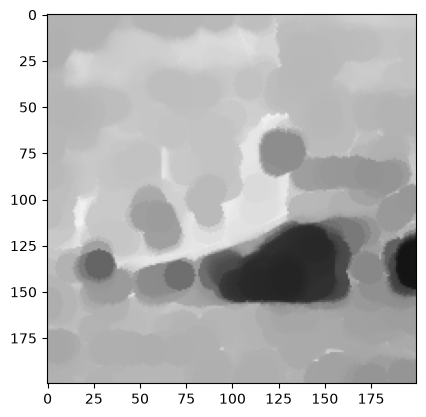

In [40]:
# Examples of functions for this work

# Binary images
# im=skio.imread('cellbin.bmp')
# im=skio.imread('cafe.bmp')

# Gray-scale images (use preferably these images)
# im=skio.imread('retina2.gif').squeeze()
im = gris_depuis_couleur(skio.imread("Images/bat200.bmp"))
# im=skio.imread('bulles.bmp')[:,:,0]
# im=gris_depuis_couleur (skio.imread('cailloux.png'))
# im=gris_depuis_couleur(skio.imread('cailloux2.png'))
# im=skio.imread('laiton.bmp')

plt.imshow(im, cmap="gray", vmin=0, vmax=255)
# viewimage(im) - could be used in place of plt.imshow is Gimp is installed.

se = strel("disk", 8)

# dilation
dil = morpho.dilation(im, se)
plt.imshow(dil, cmap="gray", vmin=0, vmax=255)

# erosion
ero = morpho.erosion(im, se)
plt.imshow(ero, cmap="gray", vmin=0, vmax=255)

# opening
open = morpho.opening(im, se)
plt.imshow(open, cmap="gray", vmin=0, vmax=255)

# closing
close = morpho.closing(im, se)
plt.imshow(close, cmap="gray", vmin=0, vmax=255)

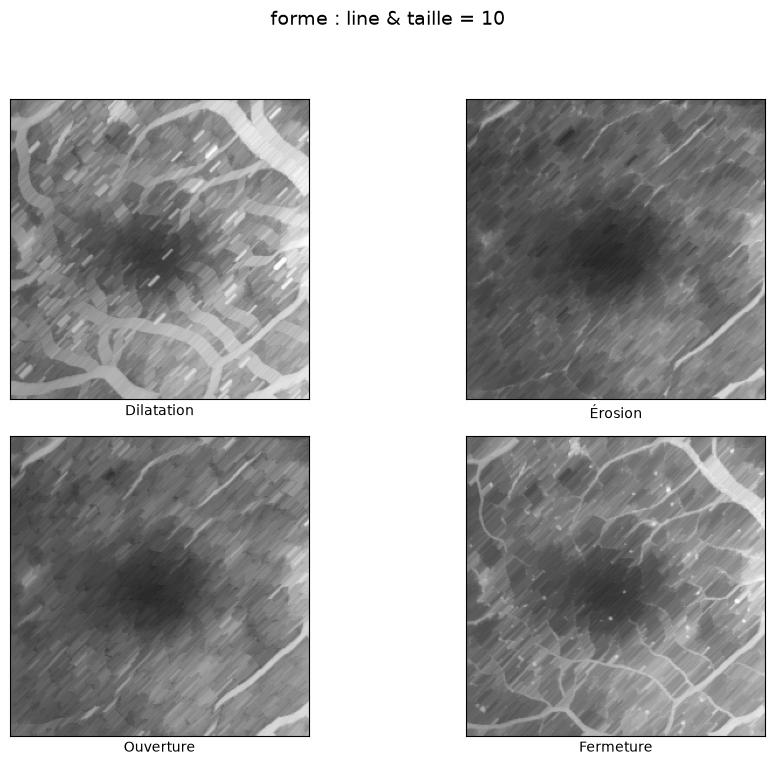

In [41]:
# Image originale
im = gris_depuis_couleur(skio.imread("Images/retina2.png"))

size = 10
shape = "line"

# Élément structurant
se = strel(
    shape,
    size,
)

# Opérations morphologiques
dil = morpho.dilation(im, se)
ero = morpho.erosion(im, se)
ouv = morpho.opening(im, se)
ferm = morpho.closing(im, se)

# Création de la figure
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# Affichage des images avec les titres en dessous
axes[0, 0].imshow(dil, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_xlabel("Dilatation")

axes[0, 1].imshow(ero, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_xlabel("Érosion")

axes[1, 0].imshow(ouv, cmap="gray", vmin=0, vmax=255)
axes[1, 0].set_xlabel("Ouverture")

axes[1, 1].imshow(ferm, cmap="gray", vmin=0, vmax=255)
axes[1, 1].set_xlabel("Fermeture")

# Masquer les axes
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

# Titre général avec les paramètres de se
fig.suptitle(f"forme : {shape} & taille = {size}", fontsize=14)

# Ajuster l'espacement pour afficher le titre général
plt.tight_layout(rect=[0, 0.03, 1, 0.93])

plt.show()

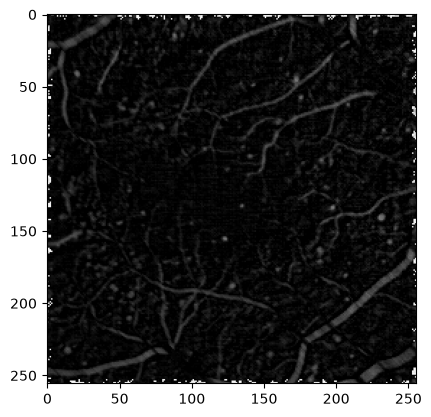

In [42]:
# Top-hat transform - In this section and all the next ones, you can change im and the parameters
im = skio.imread("Images/retina2.gif").squeeze()
t = 10
se = strel("line", t, -45)
ch = im - morpho.opening(im, se)
plt.imshow(ch, cmap="gray", vmin=0, vmax=255)

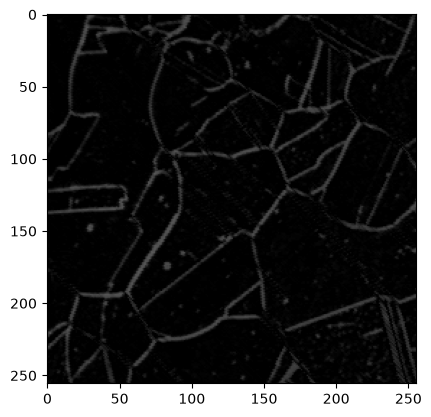

In [43]:
# Top-hat transform - In this section and all the next ones, you can change im and the parameters
im = skio.imread("Images/laiton.bmp").squeeze()
im = gris_depuis_couleur(im)
t = 10
se = strel("line", t, -45)
ch = morpho.black_tophat(im, se)
plt.imshow(ch, cmap="gray", vmin=0, vmax=255)

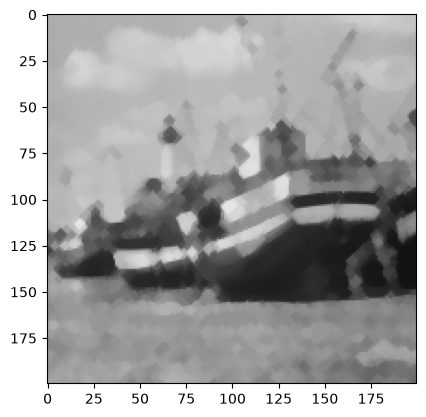

In [44]:
# Alternate Sequential Filters
# image
im = gris_depuis_couleur(skio.imread("Images/bat200.bmp"))

imt = im.copy()
N = 3
for k in range(N):
    se = strel("disk", k)
    imt = morpho.closing(morpho.opening(imt, se), se)
plt.imshow(imt, cmap="gray", vmin=0, vmax=255)

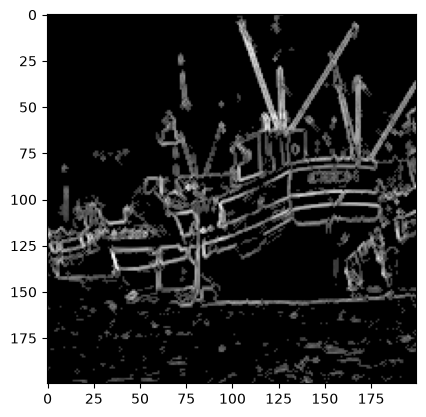

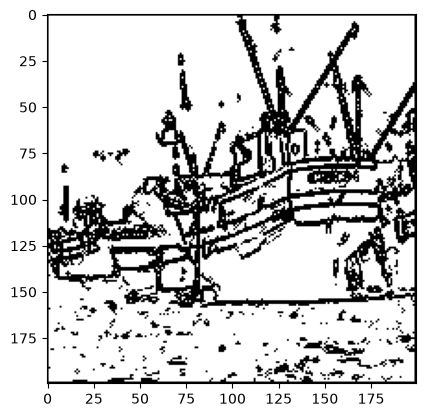

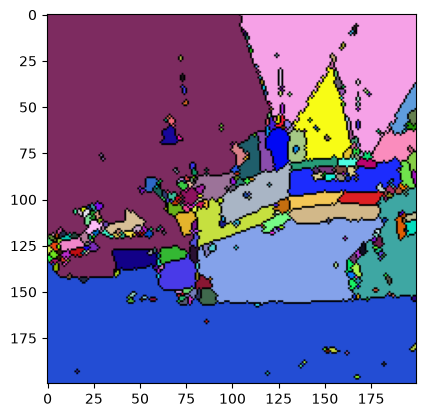

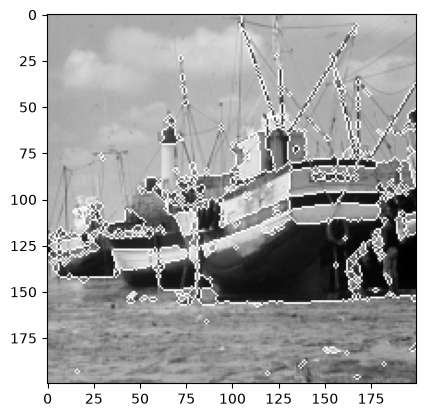

In [45]:
# Watersheds
im = gris_depuis_couleur(skio.imread("Images/bat200.bmp"))

se = morpho.disk(1)

grad = morpho.dilation(im, se) - morpho.erosion(im, se)
grad = np.int32(grad > 40) * grad
plt.imshow(grad, cmap="gray")
plt.show()

local_mini = skf.peak_local_max(255 - grad)
mask = np.zeros(im.shape, dtype=bool)
mask[tuple(local_mini.T)] = True
markers, _ = ndi.label(mask)
plt.imshow(mask, cmap="gray")
plt.show()

labels = watershed(grad, markers, mask=im, watershed_line=True)
# labels = watershed(grad, markers,watershed_line=True)
plt.imshow(couleurs_alea(labels))
plt.show()
# viewimage_color(couleurs_alea(labels)) - Utilisable si gimp est installé

# visualization of the result
segm = labels.copy()
for i in range(segm.shape[0]):
    for j in range(segm.shape[1]):
        if segm[i, j] == 0:
            segm[i, j] = 255
        else:
            segm[i, j] = 0
# superimposition of segmentation contours on the original image
contourSup = np.maximum(segm, im)
plt.imshow(contourSup, cmap="gray")

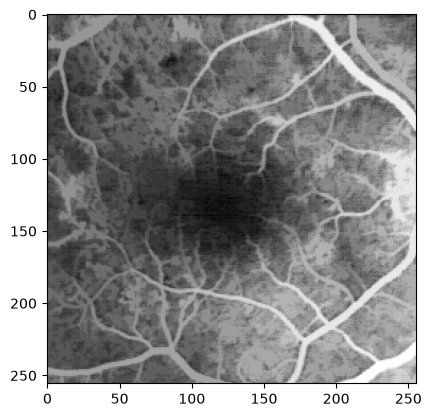

In [46]:
# reconstruction par dilatation
im = skio.imread("Images/retina2.gif").squeeze()
se4 = strel("disk", 4)
open4 = morpho.opening(im, se4)
reco = morpho.reconstruction(open4, im, method='dilation')
plt.imshow(reco, cmap="gray")

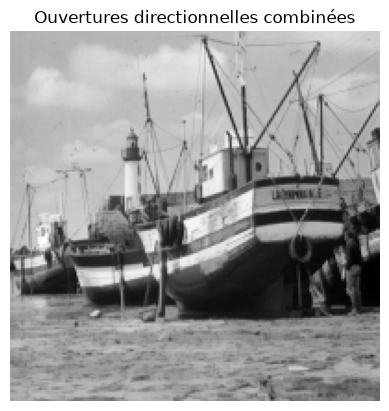

In [89]:
# 1.5
angles = [0, 45, 90, 135]
results = []

for angle in angles:
    se = strel("line", 3, angle)
    opened = morpho.opening(im, se)
    results.append(opened)

result = np.maximum.reduce(results)

plt.figure()
plt.imshow(result, cmap="gray")
plt.title("Ouvertures directionnelles combinées")
plt.axis("off")
plt.show()

True


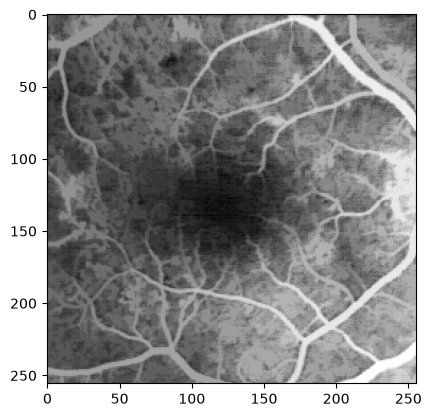

In [47]:
# reconstruction par dilatation en utilisant la reconstruction par érosion

# 1. Définir le marqueur et le masque de la reconstruction.
im = skio.imread("Images/retina2.gif").squeeze()  # masque
se4 = strel("disk", 4)
open4 = morpho.opening(im, se4)  # marqueur

# 2. Inverser les niveaux de gris du marqueur et du masque.
im_inverse = im.max() - im
open4_inverse = im.max() - open4

# 3. Calculer la reconstruction par érosion à partir du marqueur et du masque inversés.
reco_inverse = morpho.reconstruction(open4_inverse, im_inverse, method="erosion")

# 4. Inverser les niveaux de gris du résultat obtenu pour obtenir la reconstruction par dilatation.
reco_erosion = im.max() - reco_inverse

plt.imshow(reco_erosion, cmap="gray")

# -------------------

reco_directe = morpho.reconstruction(open4, im, method="dilation")

print((reco_erosion == reco_directe).all())

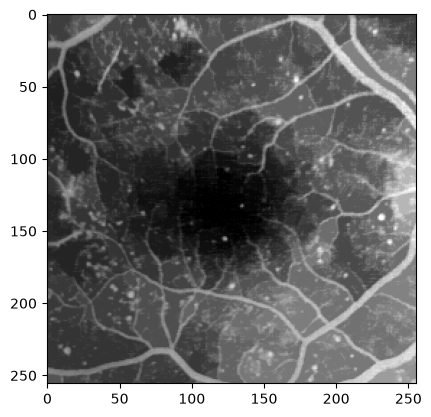

In [48]:
# reconstruction par érosion
im = skio.imread("Images/retina2.gif").squeeze()
se4 = strel("disk", 4)
open4 = morpho.closing(im, se4)
reco = morpho.reconstruction(open4, im, method='erosion')
plt.imshow(reco, cmap="gray")

True


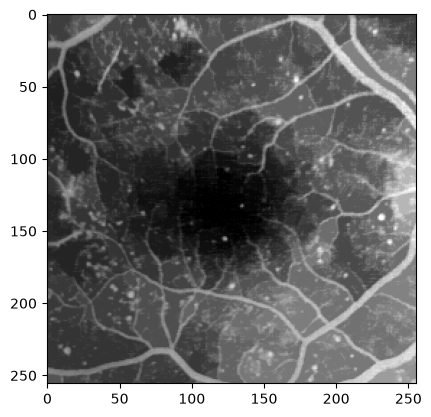

In [49]:
# reconstruction par érosion en utilisant la reconstruction par dilatation

# 1. Définir le marqueur et le masque de la reconstruction.
im = skio.imread("Images/retina2.gif").squeeze()  # masque
se4 = strel("disk", 4)
close4 = morpho.closing(im, se4)  # marqueur

# 2. Inverser les niveaux de gris du marqueur et du masque.
im_inverse = im.max() - im
close4_inverse = im.max() - close4

# 3. Calculer la reconstruction par dilatation à partir du marqueur et du masque inversés.
reco_inverse = morpho.reconstruction(close4_inverse, im_inverse, method="dilation")

# 4. Inverser les niveaux de gris du résultat obtenu pour obtenir la reconstruction par érosion.
reco_erosion = im.max() - reco_inverse

plt.imshow(reco_erosion, cmap="gray")

# -------------------

reco_directe = morpho.reconstruction(close4, im, method="erosion")

print((reco_erosion == reco_directe).all())

/var/folders/yn/t0p0m4xx5m508mzpsgpckz940000gn/T/ipykernel_28213/844301569.py:100: FutureWarning: `square` is deprecated since version 0.25 and will be removed in version 0.27. Use `skimage.morphology.footprint_rectangle` instead.
  return morpho.square(taille)


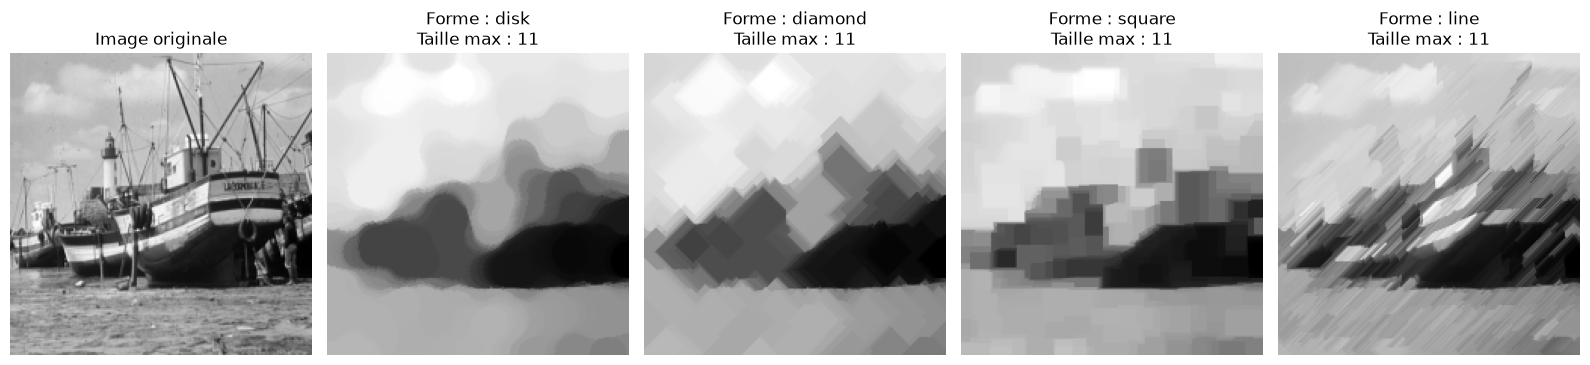

In [50]:
# --------------------------------------------------
# 1. Lire l'image
# --------------------------------------------------
im = skio.imread("Images/bat200.bmp", as_gray=True)


# --------------------------------------------------
# 2. Définir le filtre alterné séquentiel
# --------------------------------------------------
def filtre_alterne(im, forme="disk", taille_max=5):
    resultat = im.copy()

    for rayon in range(1, taille_max + 1):
        taille = 2 * rayon + 1

        # Élément structurant
        se = strel(forme, taille)

        # Ouverture suivie d'une fermeture
        resultat = morpho.opening(resultat, se)
        resultat = morpho.closing(resultat, se)

    return resultat


# --------------------------------------------------
# 3. Tester différentes formes
# --------------------------------------------------
formes = ["disk", "diamond", "square", "line"]
taille_max = 5

fig, axes = plt.subplots(1, len(formes) + 1, figsize=(16, 5))

axes[0].imshow(im, cmap="gray")
axes[0].set_title("Image originale")
axes[0].axis("off")

for i, forme in enumerate(formes):
    resultat = filtre_alterne(im, forme, taille_max)

    axes[i + 1].imshow(resultat, cmap="gray")
    axes[i + 1].set_title(f"Forme : {forme}\nTaille max : {2 * taille_max + 1}")
    axes[i + 1].axis("off")

plt.tight_layout()
plt.show()

/var/folders/yn/t0p0m4xx5m508mzpsgpckz940000gn/T/ipykernel_28213/844301569.py:100: FutureWarning: `square` is deprecated since version 0.25 and will be removed in version 0.27. Use `skimage.morphology.footprint_rectangle` instead.
  return morpho.square(taille)


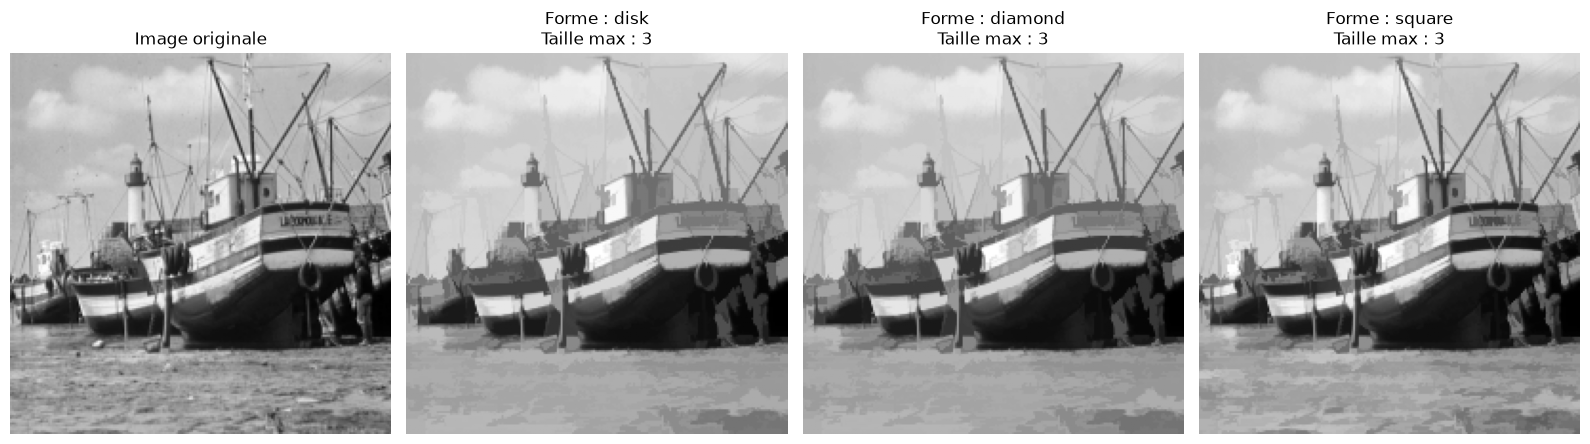

In [51]:
# --------------------------------------------------
# 1. Lire l'image
# --------------------------------------------------
im = skio.imread("Images/bat200.bmp", as_gray=True)


# --------------------------------------------------
# 2. Définir le filtre alterné séquentiel
# --------------------------------------------------
def filtre_alterne(im, forme="disk", taille_max=5):
    resultat = im.copy()

    for rayon in range(1, taille_max + 1):
        taille = 2 * rayon + 1

        # Élément structurant
        se = strel(forme, taille)

        # Ouverture suivie d'une reconstruction par dilatation
        ouvert = morpho.opening(resultat, se)
        resultat = morpho.reconstruction(ouvert, resultat, method="dilation")

        # Fermeture suivie d'une reconstruction par érosion
        ferme = morpho.closing(resultat, se)
        resultat = morpho.reconstruction(ferme, resultat, method="erosion")

    return resultat


# --------------------------------------------------
# 3. Tester différentes formes
# --------------------------------------------------
formes = ["disk", "diamond", "square"]
taille_max = 1

fig, axes = plt.subplots(1, len(formes) + 1, figsize=(16, 5))

axes[0].imshow(im, cmap="gray")
axes[0].set_title("Image originale")
axes[0].axis("off")

for i, forme in enumerate(formes):
    resultat = filtre_alterne(im, forme, taille_max)

    axes[i + 1].imshow(resultat, cmap="gray")
    axes[i + 1].set_title(f"Forme : {forme}\nTaille max : {2 * taille_max + 1}")
    axes[i + 1].axis("off")

plt.tight_layout()
plt.show()

<Figure size 1200x500 with 0 Axes>

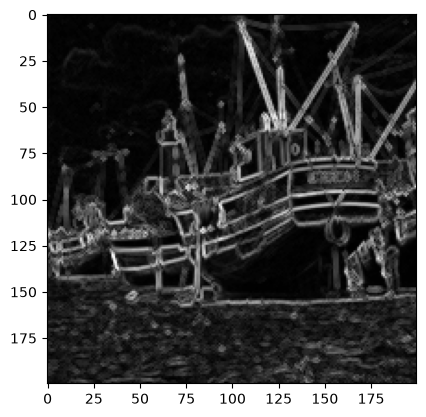

<Figure size 1200x500 with 0 Axes>

In [52]:
# 4.1

im = skio.imread("Images/bat200.bmp", as_gray=True)
se = strel("disk", 1)

dil = morpho.dilation(im, se)
ero = morpho.erosion(im, se)
gradient = dil - ero

plt.imshow(gradient, cmap="gray")
plt.figure(figsize=(12, 5))

/var/folders/yn/t0p0m4xx5m508mzpsgpckz940000gn/T/ipykernel_28213/844301569.py:100: FutureWarning: `square` is deprecated since version 0.25 and will be removed in version 0.27. Use `skimage.morphology.footprint_rectangle` instead.
  return morpho.square(taille)


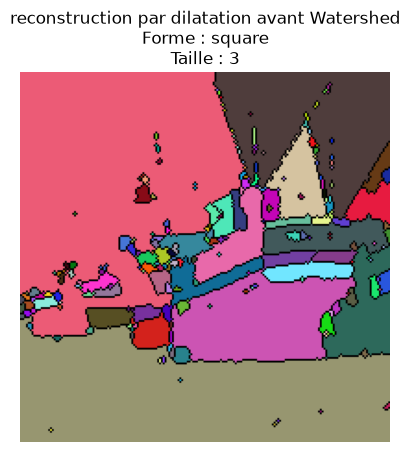

In [53]:
# 4.3

# Watersheds
im = gris_depuis_couleur(skio.imread("Images/bat200.bmp"))

se = morpho.disk(1)

forme = "square"
taille = 3

se4 = strel(forme, taille)

open4 = morpho.opening(im,se4);
im_filtre = morpho.reconstruction(open4, im, method="dilation")

grad = morpho.dilation(im_filtre, se) - morpho.erosion(im_filtre, se)
grad = np.int32(grad > 40) * grad

# grad = morpho.closing(grad, se4)

plt.imshow(grad, cmap="gray")

local_mini = skf.peak_local_max(255 - grad)
mask = np.zeros(im.shape, dtype=bool)
mask[tuple(local_mini.T)] = True
markers, _ = ndi.label(mask)
plt.imshow(mask, cmap="gray")

labels = watershed(grad, markers, mask=im, watershed_line=True)
# labels = watershed(grad, markers,watershed_line=True)
plt.imshow(couleurs_alea(labels))
plt.title(f"reconstruction par dilatation avant Watershed\nForme : {forme}\nTaille : {taille}")
plt.axis("off")
plt.show()
# viewimage_color(couleurs_alea(labels)) - Utilisable si gimp est installé

# visualization of the result
segm = labels.copy()
for i in range(segm.shape[0]):
    for j in range(segm.shape[1]):
        if segm[i, j] == 0:
            segm[i, j] = 255
        else:
            segm[i, j] = 0
# superimposition of segmentation contours on the original image
contourSup = np.maximum(segm, im)
plt.show()

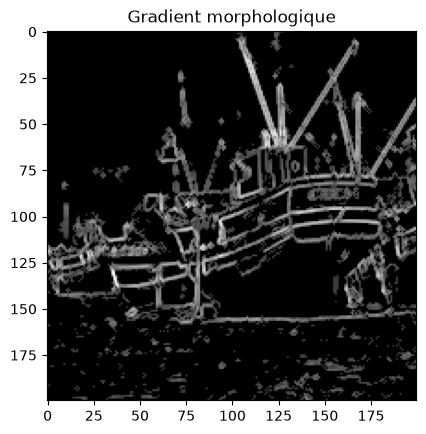

h = 5 : 325 marqueurs


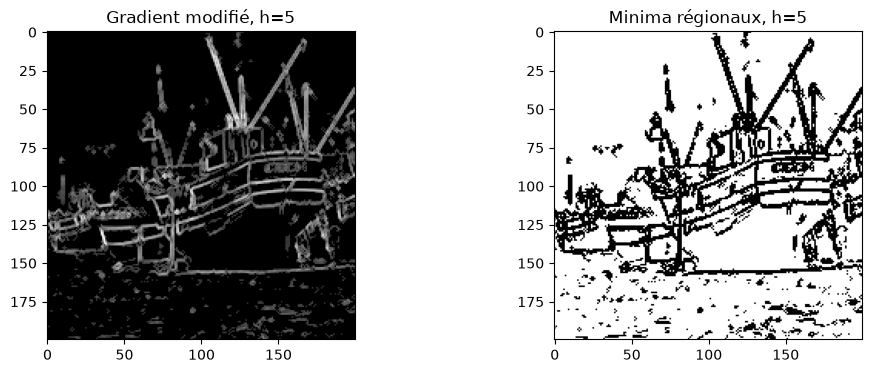

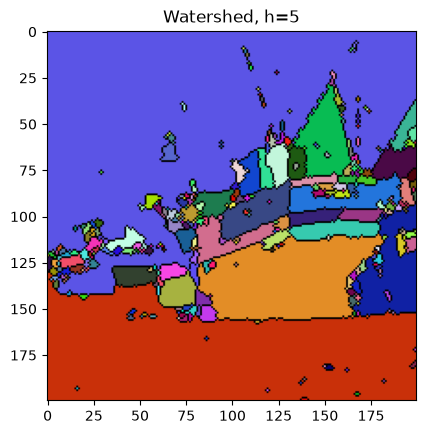

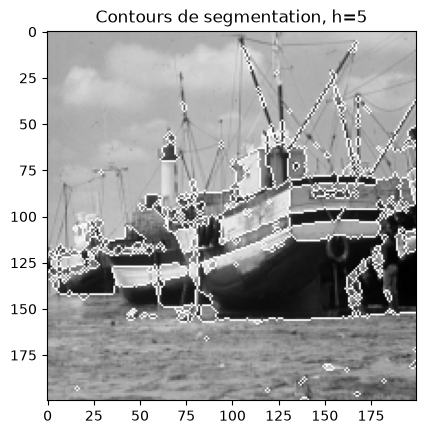

h = 20 : 282 marqueurs


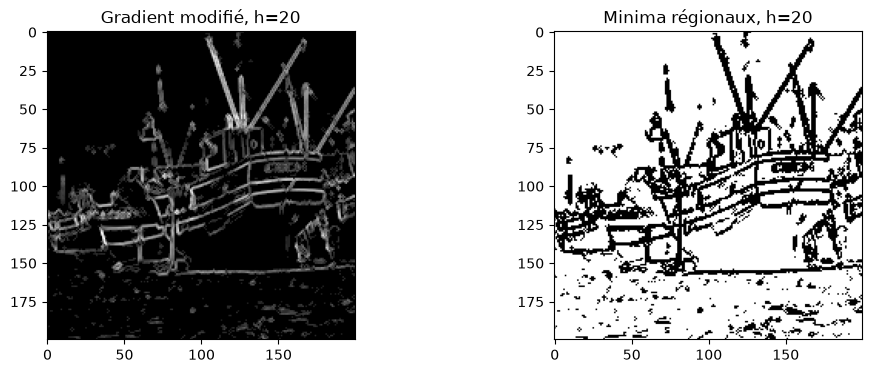

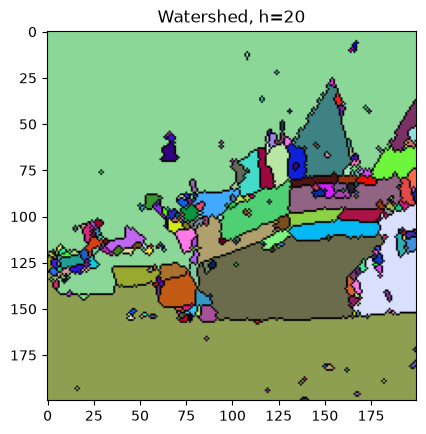

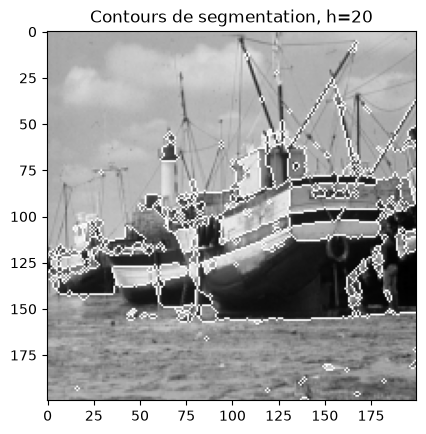

In [57]:
# 4.4 - Watershed avec suppression des minima régionaux

im = gris_depuis_couleur(skio.imread("Images/bat200.bmp"))

# 1. Calcul du gradient morphologique
se = morpho.disk(1)
grad = morpho.dilation(im, se) - morpho.erosion(im, se)
grad = np.int32(grad > 40) * grad

plt.imshow(grad, cmap="gray")
plt.title("Gradient morphologique")
plt.show()

# 2. Comparaison pour h = 5 et h = 20
for h in [5, 20]:

    # Suppression des minima de faible dynamique
    grad_h = morpho.reconstruction(
        grad + h, grad, method="erosion"
    )

    # Recherche des minima régionaux
    local_mini = morpho.local_minima(grad_h)

    # Création des marqueurs
    markers, nb = ndi.label(local_mini)
    print(f"h = {h} : {nb} marqueurs")

    # Affichage du gradient modifié et des minima
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(grad_h, cmap="gray")
    plt.title(f"Gradient modifié, h={h}")

    plt.subplot(1, 2, 2)
    plt.imshow(local_mini, cmap="gray")
    plt.title(f"Minima régionaux, h={h}")

    plt.show()

    # 3. Application du watershed
    labels = watershed(
        grad_h, markers, mask=im, watershed_line=True
    )

    # Affichage de la segmentation
    plt.figure()
    plt.imshow(couleurs_alea(labels))
    plt.title(f"Watershed, h={h}")
    plt.show()

    # 4. Affichage des contours sur l'image originale
    segm = np.where(labels == 0, 255, 0)
    contourSup = np.maximum(segm, im)

    plt.figure()
    plt.imshow(contourSup, cmap="gray")
    plt.title(f"Contours de segmentation, h={h}")
    plt.show()

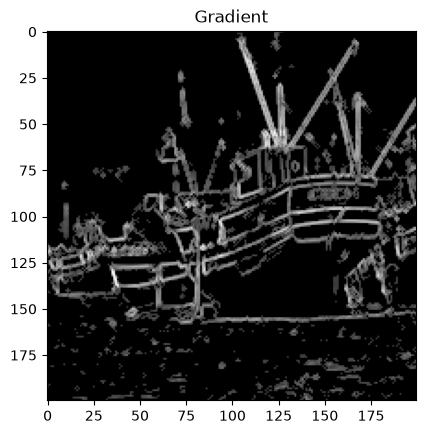

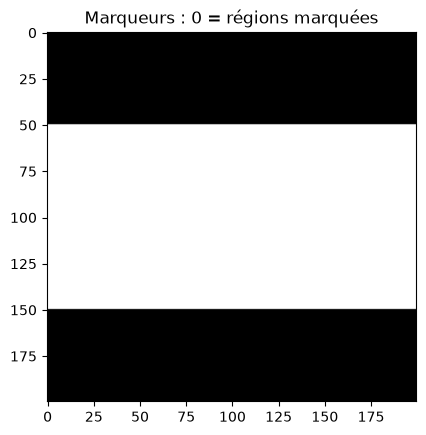

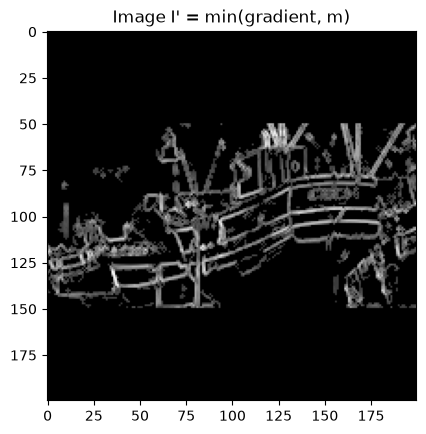

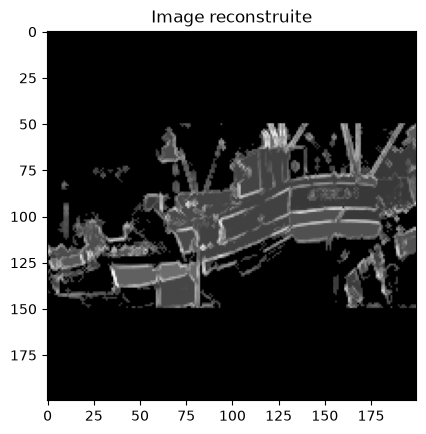

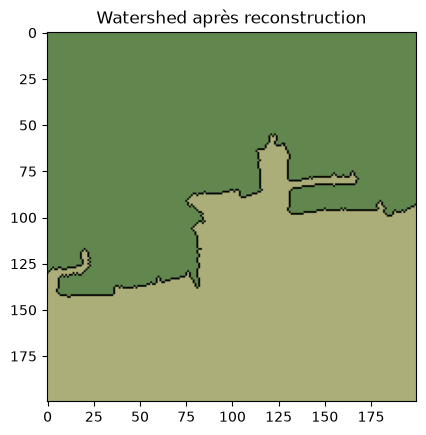

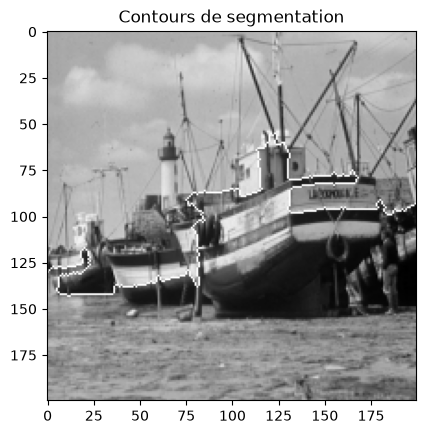

In [ ]:
# 4.5

# Watersheds avec reconstruction morphologique

im = gris_depuis_couleur(skio.imread("Images/bat200.bmp"))

se = morpho.disk(1)

# Calcul du gradient
grad = morpho.dilation(im, se) - morpho.erosion(im, se)
grad = np.int32(grad > 40) * grad

plt.imshow(grad, cmap="gray")
plt.title("Gradient")
plt.show()

# 1. Définition des marqueurs
# 255 partout, 0 dans les régions marquées
m = np.full(im.shape, 255, dtype=np.uint8)

# Marqueurs du ciel et de la mer
m[0:50, 0:200] = 0
m[150:200, 0:200] = 0

plt.imshow(m, cmap="gray")
plt.title("Marqueurs : 0 = régions marquées")
plt.show()

# 2. I' = I ∧ m
I_prime = np.minimum(grad, m)

plt.imshow(I_prime, cmap="gray")
plt.title("Image I' = min(gradient, m)")
plt.show()

# 3. Reconstruction morphologique par érosion
recon = morpho.reconstruction(
    m.astype(np.float64),
    I_prime.astype(np.float64),
    method="erosion"
)

plt.imshow(recon, cmap="gray")
plt.title("Image reconstruite")
plt.show()

# 4. Création des labels des marqueurs
markers = np.zeros(im.shape, dtype=np.int32)
markers[0:50, 0:200] = 1       # Ciel
markers[150:200, 0:200] = 2    # Mer

# 5. Watershed sur l'image reconstruite
labels = watershed(
    recon,
    markers,
    mask=im > 0,
    watershed_line=True
)

plt.imshow(couleurs_alea(labels))
plt.title("Watershed après reconstruction")
plt.show()

# 6. Superposition des contours sur l'image originale
segm = np.where(labels == 0, 255, 0).astype(np.uint8)
contourSup = np.maximum(segm, im)

plt.imshow(contourSup, cmap="gray")
plt.title("Contours de segmentation")
plt.show()